# Baseline Isolation Forest — IEEE-CIS Fraud Detection


## Objective

Load the IEEE-CIS Fraud Detection dataset, explore it deeply, and build a baseline
`scikit-learn` **Isolation Forest** model


In [5]:
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RNG_SEED = 42
np.random.seed(RNG_SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


/Users/joyce/Desktop/FraudDetection/Unsupervised-fraud-detection-the-outliers/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
DATA_DIR = "../../data/ieee-fraud-detection"

t0 = time.perf_counter()
tx = pd.read_csv(f"{DATA_DIR}/train_transaction.csv")
idt = pd.read_csv(f"{DATA_DIR}/train_identity.csv")
df = tx.merge(idt, on="TransactionID", how="left")
print(f"Loaded + merged in {time.perf_counter() - t0:.1f}s")
print(f"Merged shape: {df.shape}")


Loaded + merged in 11.9s
Merged shape: (590540, 434)


# Part 1: Data Exploration

## 1. Dataset — Initial Checks

In [7]:
print("Shape:", df.shape)
df.dtypes.value_counts()


Shape: (590540, 434)


float64    399
str         31
int64        4
Name: count, dtype: int64

In [8]:
df[["TransactionAmt", "card1", "card2", "card3", "card5"]].describe()


,TransactionAmt,card1,card2,card3,card5
count,590540.000000,590540.000000,581607.000000,588975.000000,586281.000000
mean,135.027176,9898.734658,362.555488,153.194925,199.278897
std,239.162522,4901.170153,157.793246,11.336444,41.244453
min,0.251000,1000.000000,100.000000,100.000000,100.000000
25%,43.321000,6019.000000,214.000000,150.000000,166.000000
50%,68.769000,9678.000000,361.000000,150.000000,226.000000
75%,125.000000,14184.000000,512.000000,150.000000,226.000000
max,31937.391000,18396.000000,600.000000,231.000000,237.000000


In [9]:
fraud_counts = df["isFraud"].value_counts()
fraud_pct = df["isFraud"].mean() * 100
imbalance_ratio = fraud_counts[0] / fraud_counts[1]

print(fraud_counts)
print(f"\nFraud rate: {fraud_pct:.3f}%")
print(f"Imbalance ratio (non-fraud : fraud): {imbalance_ratio:.1f} : 1")


isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud rate: 3.499%
Imbalance ratio (non-fraud : fraud): 27.6 : 1


**Raw / interpretable features** include `TransactionAmt`, `ProductCD`, card-related
columns (`card1`-`card6`), address/email/device columns, the `C`/`D`/`M` columns, and
the `id_*` identity columns.

**Anonymized features** are `V1`-`V339` — engineered by the competition host with no
disclosed meaning.


In [10]:
v_cols = [c for c in df.columns if c.startswith("V")]
raw_cols = [c for c in df.columns if c not in v_cols and c not in ("TransactionID", "isFraud")]
print(f"Anonymized V columns: {len(v_cols)}")
print(f"Raw / interpretable columns: {len(raw_cols)}")


Anonymized V columns: 339
Raw / interpretable columns: 93


## 2. Class Imbalance

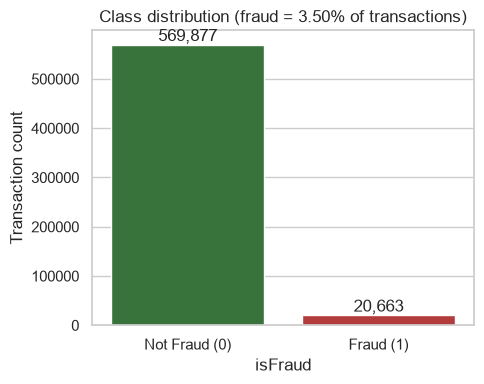

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=fraud_counts.index.astype(str), y=fraud_counts.values, ax=ax,
            hue=fraud_counts.index.astype(str), palette=["#2E7D32", "#C62828"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Not Fraud (0)", "Fraud (1)"])
ax.set_ylabel("Transaction count")
ax.set_title(f"Class distribution (fraud = {fraud_pct:.2f}% of transactions)")
for i, v in enumerate(fraud_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


**Findings:** Fraud is rare — about 3.5% of transactions are fraudulent, a roughly
27:1 imbalance. 

Therefore, ranking-based metrics (ROC-AUC, precision-recall AUC, precision at a fixed review budget) should be used for evaluation;
raw accuracy would be meaningless since labeling everything "not fraud" already
scores ~96.5%. It also means the top-K anomalies inspected in Part 3 should contain
far more fraud than the base rate if Isolation Forest is picking up real signal.


## 3. Transaction Amount Distribution

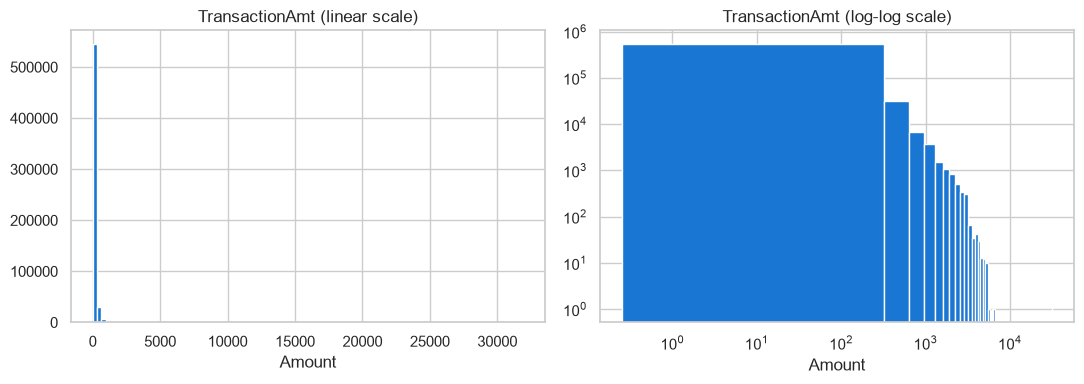

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["TransactionAmt"], bins=100, color="#1976D2")
axes[0].set_title("TransactionAmt (linear scale)")
axes[0].set_xlabel("Amount")

axes[1].hist(df["TransactionAmt"], bins=100, color="#1976D2")
axes[1].set_yscale("log")
axes[1].set_xscale("log")
axes[1].set_title("TransactionAmt (log-log scale)")
axes[1].set_xlabel("Amount")
plt.tight_layout()
plt.show()

df["TransactionAmt"].describe()


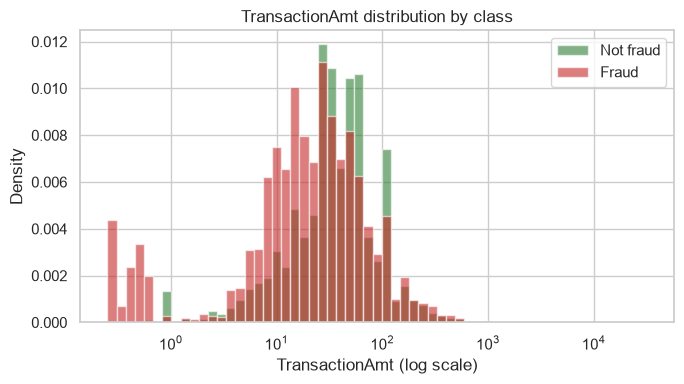

Fraud mean/median amt:   149.24 / 75.0
Non-fraud mean/median amt: 134.51 / 68.5


In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.logspace(np.log10(df["TransactionAmt"].min()), np.log10(df["TransactionAmt"].max()), 60)
ax.hist(df.loc[df.isFraud == 0, "TransactionAmt"], bins=bins, alpha=0.6, label="Not fraud", color="#2E7D32", density=True)
ax.hist(df.loc[df.isFraud == 1, "TransactionAmt"], bins=bins, alpha=0.6, label="Fraud", color="#C62828", density=True)
ax.set_xscale("log")
ax.set_xlabel("TransactionAmt (log scale)")
ax.set_ylabel("Density")
ax.set_title("TransactionAmt distribution by class")
ax.legend()
plt.tight_layout()
plt.show()

print("Fraud mean/median amt:  ", df.loc[df.isFraud == 1, "TransactionAmt"].mean().round(2),
      "/", df.loc[df.isFraud == 1, "TransactionAmt"].median().round(2))
print("Non-fraud mean/median amt:", df.loc[df.isFraud == 0, "TransactionAmt"].mean().round(2),
      "/", df.loc[df.isFraud == 0, "TransactionAmt"].median().round(2))


**Findings:** `TransactionAmt` is heavily right-skewed (mean ≈ \$135 but a max above
\$31,900). Fraud
amounts run slightly *higher* on average than non-fraud (mean \$149 vs. \$135; median
\$75 vs. \$68.50), but the two distributions overlap substantially — amount alone is a
weak discriminator.


## 4. Categorical Features

> **Leakage note:** fraud rate by category below is computed purely for exploration.
> It is never fed back into the model as a feature in Part 2.


In [14]:
for col in ["ProductCD", "card4", "card6"]:
    summary = df.groupby(col)["isFraud"].agg(["mean", "count"]).rename(columns={"mean": "fraud_rate"})
    summary["fraud_rate_pct"] = (summary["fraud_rate"] * 100).round(2)
    print(f"--- {col} ---")
    print(summary.sort_values("fraud_rate", ascending=False))
    print()


--- ProductCD ---
           fraud_rate   count  fraud_rate_pct
ProductCD                                    
C            0.116873   68519           11.69
S            0.058996   11628            5.90
H            0.047662   33024            4.77
R            0.037826   37699            3.78
W            0.020399  439670            2.04

--- card4 ---
                  fraud_rate   count  fraud_rate_pct
card4                                               
discover            0.077282    6651            7.73
visa                0.034756  384767            3.48
mastercard          0.034331  189217            3.43
american express    0.028698    8328            2.87

--- card6 ---
                 fraud_rate   count  fraud_rate_pct
card6                                              
credit             0.066785  148986            6.68
debit              0.024263  439938            2.43
charge card        0.000000      15            0.00
debit or credit    0.000000      30            0.00


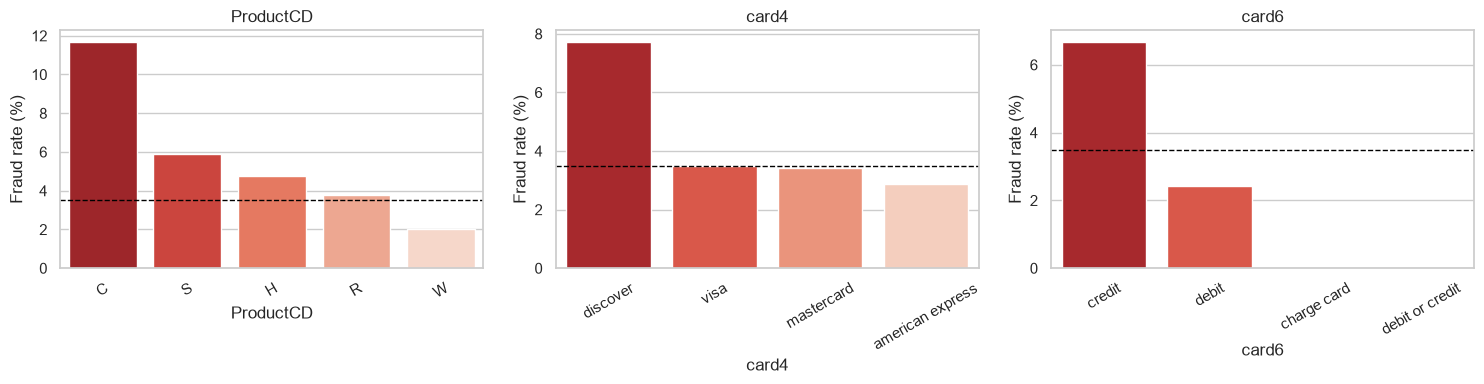

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["ProductCD", "card4", "card6"]):
    rates = df.groupby(col)["isFraud"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, hue=rates.index.astype(str),
                palette="Reds_r", legend=False)
    ax.axhline(fraud_pct, color="black", linestyle="--", linewidth=1, label="overall rate")
    ax.set_ylabel("Fraud rate (%)")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


**Findings:** category-level fraud rates vary a lot more than overall volume would
suggest. `ProductCD == "C"` has an 11.7% fraud rate versus the overall 3.5% baseline
(and versus 2.0% for the much larger `ProductCD == "W"` segment). `card4 == "discover"`
(7.7%) and `card6 == "credit"` (6.7% vs. 2.4% for debit) also run well above baseline.

## 5. Missing Values

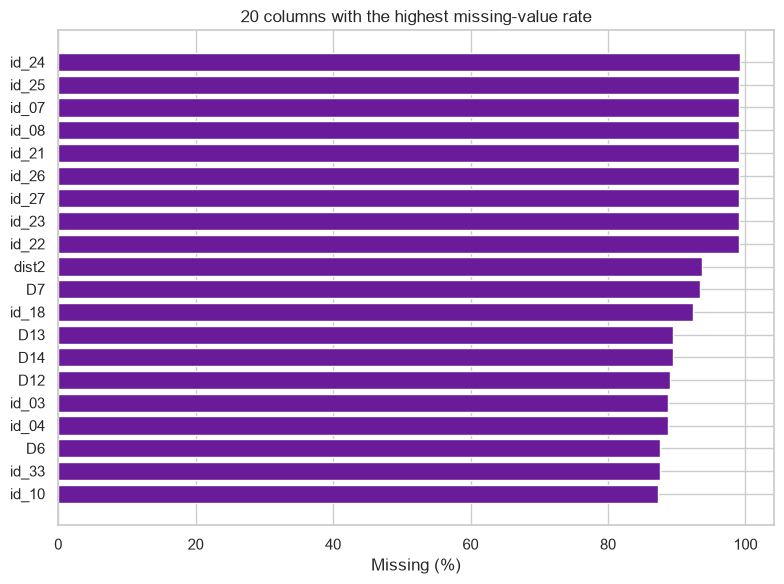

Columns with >90% missing: 12 / 434


In [16]:
missing_pct = df.isna().mean().sort_values(ascending=False) * 100
top20 = missing_pct.head(20)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top20.index[::-1], top20.values[::-1], color="#6A1B9A")
ax.set_xlabel("Missing (%)")
ax.set_title("20 columns with the highest missing-value rate")
plt.tight_layout()
plt.show()

n_over_90 = (missing_pct > 90).sum()
print(f"Columns with >90% missing: {n_over_90} / {df.shape[1]}")


In [17]:
row_missing_pct = df.isna().mean(axis=1)
print("Mean fraction of columns missing per row:")
print(f"  Fraud rows:     {row_missing_pct[df.isFraud == 1].mean():.3f}")
print(f"  Non-fraud rows: {row_missing_pct[df.isFraud == 0].mean():.3f}")

top_missing_cols = missing_pct.head(10).index.tolist()
comparison = pd.DataFrame({
    "missing_pct_overall": missing_pct[top_missing_cols],
    "missing_pct_fraud": [df.loc[df.isFraud == 1, c].isna().mean() * 100 for c in top_missing_cols],
    "missing_pct_nonfraud": [df.loc[df.isFraud == 0, c].isna().mean() * 100 for c in top_missing_cols],
})
comparison


Mean fraction of columns missing per row:
  Fraud rows:     0.373
  Non-fraud rows: 0.454


,missing_pct_overall,missing_pct_fraud,missing_pct_nonfraud
id_24,99.196159,98.054494,99.237555
id_25,99.130965,97.981900,99.172628
id_07,99.127070,97.938344,99.170172
id_08,99.127070,97.938344,99.170172
id_21,99.126393,97.938344,99.169470
id_26,99.125715,97.943183,99.168593
id_27,99.124699,97.938344,99.167715
id_23,99.124699,97.938344,99.167715
id_22,99.124699,97.938344,99.167715
dist2,93.628374,81.943571,94.052050


**Findings:** 12 columns (mostly `id_*` identity fields and `dist2`) are missing in
over 90% of rows and are dropped before modeling (Part 2). Missingness carry a
weak fraud signal: fraud rows are,
on average, slightly *more complete* than non-fraud rows (37% of columns missing vs.
45%)

## 6. Anonymized Features: V1–V339

(1) a correlation heatmap of a **randomly sampled** subset of `V` columns,
to see how redundant the block is without cherry-picking which columns to look at;
(2) each `V` column's correlation with `isFraud` to see which features are worth a closer look; and
(3) distribution/spread plots, split by class, for the features that come out most
correlated with fraud in step 2.

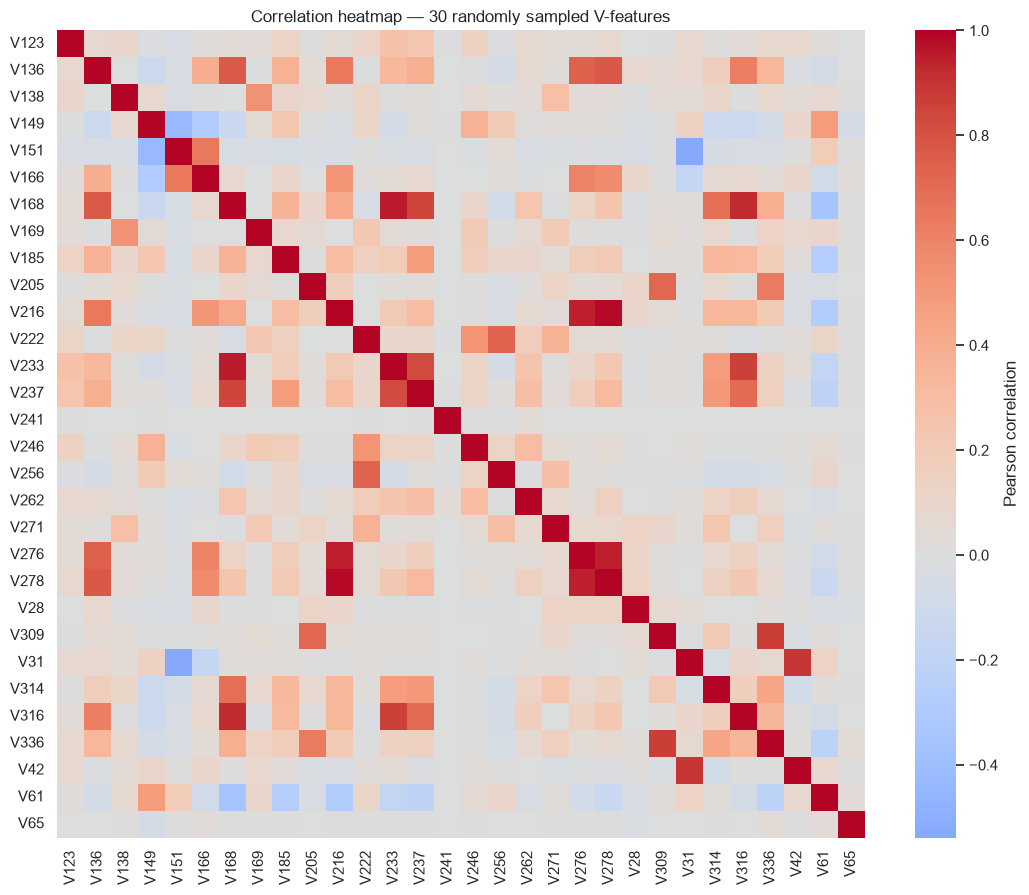

In [18]:
N_RANDOM_V = 30
rng_sample = np.random.default_rng(RNG_SEED)
random_v_cols = sorted(rng_sample.choice(v_cols, size=N_RANDOM_V, replace=False).tolist())

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(df[random_v_cols].corr(), cmap="coolwarm", center=0, ax=ax, square=True,
            cbar_kws={"label": "Pearson correlation"})
ax.set_title(f"Correlation heatmap — {N_RANDOM_V} randomly sampled V-features")
plt.tight_layout()
plt.show()


In [19]:
# EDA only: correlation with isFraud, used to decide what to look at next -- never fed
# back into Part 2 as a training feature.
fraud_corr = df[v_cols].corrwith(df["isFraud"])
fraud_corr = fraud_corr.reindex(fraud_corr.abs().sort_values(ascending=False).index)

print("Top 15 V-features by |correlation with isFraud|:")
fraud_corr.head(15)


Top 15 V-features by |correlation with isFraud|:


V257    0.383060
V246    0.366878
V244    0.364129
V242    0.360590
V201    0.328005
V200    0.318783
V189    0.308219
V188    0.303582
V258    0.297151
V45     0.281832
V158    0.278066
V156    0.275952
V149    0.273282
V228    0.268861
V44     0.260376
dtype: float64

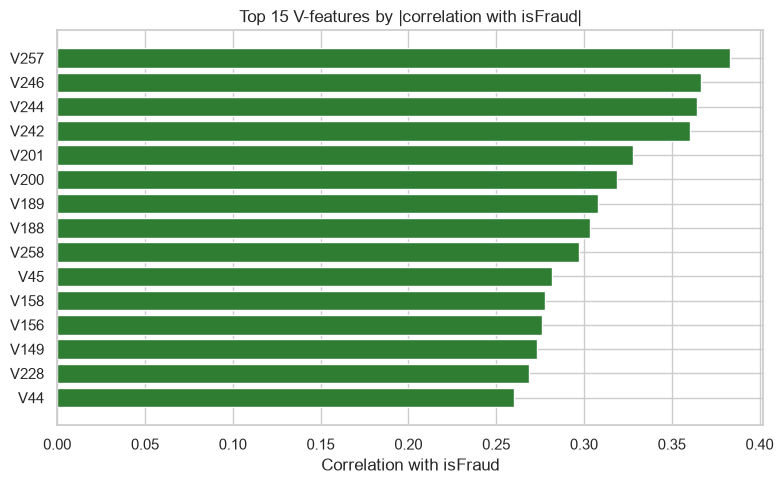

In [20]:
top15 = fraud_corr.head(15)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#C62828" if v < 0 else "#2E7D32" for v in top15.values]
ax.barh(top15.index[::-1], top15.values[::-1], color=colors[::-1])
ax.set_xlabel("Correlation with isFraud")
ax.set_title("Top 15 V-features by |correlation with isFraud|")
plt.tight_layout()
plt.show()


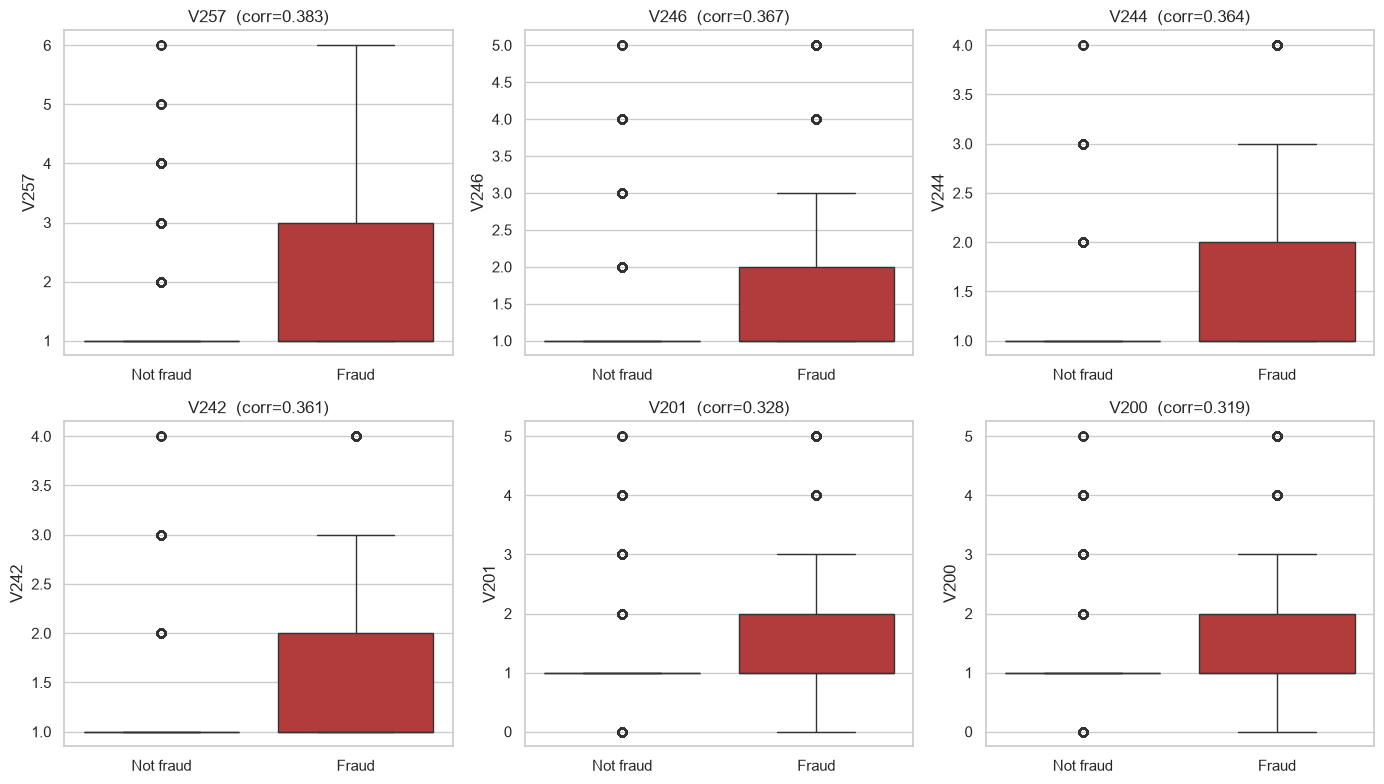

In [21]:
top_fraud_corr_cols = fraud_corr.head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), top_fraud_corr_cols):
    plot_df = df[[col, "isFraud"]].dropna()
    lo, hi = plot_df[col].quantile([0.01, 0.99])
    plot_df = plot_df[plot_df[col].between(lo, hi)]
    sns.boxplot(data=plot_df, x="isFraud", y=col, ax=ax, hue="isFraud",
                palette={0: "#2E7D32", 1: "#C62828"}, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Not fraud", "Fraud"])
    ax.set_xlabel("")
    ax.set_title(f"{col}  (corr={fraud_corr[col]:.3f})")
plt.tight_layout()
plt.show()


**Findings:** the randomly sampled correlation heatmap shows the `V` block is *not*
uniformly redundant — most of the 30×30 grid is close to zero (grey) — but a handful of
tight clusters stand out: `V276`/`V278` run close to perfectly correlated (~0.9+), with
`V168`, `V216`, `V233`, `V237`, `V314`, and `V316` each forming their own visible
same-direction blocks, while `V149`, `V151`, `V166`, and `V31` form a distinct
*negatively* correlated cluster (down to roughly -0.5). So redundancy is real but
concentrated in specific feature groups rather than dataset-wide — consistent with
these columns being aggregates of the same underlying signal over different windows.

The correlation-with-fraud ranking is dominated by a tight group, all **positively**
correlated (no negative entries make the top 15): `V257` (0.383), `V246` (0.367),
`V244` (0.364), `V242` (0.361), `V201` (0.328), `V200` (0.319), `V189` (0.308),
`V188` (0.304), `V258` (0.297), `V45` (0.282), `V158` (0.278), `V156` (0.276),
`V149` (0.273), `V228` (0.269), `V44` (0.260) — noticeably stronger correlations than
any single raw/interpretable feature explored so far (`TransactionAmt` barely separates
the classes at all by comparison).

The box plots for the top 6 (`V257`, `V246`, `V244`, `V242`, `V201`, `V200`) make the
pattern vivid and consistent across all six: for **non-fraud** transactions the box is
collapsed to a flat line at 1 (the 25th-75th percentile is exactly 1, with only a sparse
scatter of outlier dots reaching 4-6), while for **fraud** the box visibly widens — the
median shifts to 1-2 and the interquartile range reaches roughly 2-3. In other words,
most legitimate transactions show exactly the baseline value on these columns, while
fraudulent ones show meaningfully higher and more variable values.

## 7. Exploration Write-Up

**Summary of findings**

- Fraud is rare (3.5%, ~27:1 imbalance), so the model will be judged on ranking metrics
  (AUC, precision at a fixed budget) rather than accuracy.
- `TransactionAmt` is heavily right-skewed; fraud trends slightly higher in amount but
  overlaps heavily with non-fraud — a weak signal on its own.
- Categorical rarity matters more than category identity: `ProductCD == C`,
  `card4 == discover`, and `card6 == credit` all show fraud rates 2-3x the baseline
  despite being minority segments.
- Missingness is informative but counterintuitive — fraud rows tend to be *more* complete
  than non-fraud rows, not less. 
- The anonymized `V` block is redundant in pockets rather than uniformly — the randomly
  sampled heatmap shows a few tight clusters (e.g. `V276`/`V278` near-perfectly
  correlated, plus a `V149`/`V151`/`V166`/`V31` cluster that's *negatively* correlated)
  against a mostly-independent background. More importantly, a group of ~15 V-features
  (`V257`, `V246`, `V244`, `V242`, `V201`, `V200`, `V189`, `V188`, `V258`, `V45`, `V158`,
  `V156`, `V149`, `V228`, `V44`) correlate with `isFraud` far more strongly (0.26-0.38)
  than any raw/interpretable feature explored so far, and the box plots show why: these
  columns sit at a flat baseline value of 1 for almost all non-fraud transactions, while
  fraud transactions show a visibly wider, higher spread (median 1-2, IQR up to 2-3).
  This is the clearest, most interpretable signal found in the entire exploration.


# Part 2: Training Plan

Proposing three different training strategies, the comparison is meant to
show how much feature engineering actually matters for Isolation Forest on this
dataset, rather than committing to one pipeline up front.

**Shared data preparation**

- Exclude `TransactionID` (identifier), `isFraud` (label), `TransactionDT` (timestamp).
- Drop columns missing in more than 90% of rows (same threshold as the first attempt).
- Everything else — which columns are kept, how they're encoded — is decided
  separately by each strategy below.

**Three training strategies**

1. **Baseline -- Full high-dimensional set, no reduction** — use every remaining column with only
   the minimal encoding needed to make it numeric. No feature selection, no
   dimensionality reduction.
2. **Categorical features only, one-hot encoded** — Part 1 §4 showed some categories
   have a large effect on fraud rate; this strategy trains purely on one-hot-encoded
   categorical columns, with no numeric columns at all.
3. **Correlation-based reduction across engineered feature families** — from the `V`,
   `C`, `D`, `M`, and `id_` columns, keep only those most correlated with `isFraud`
   (EDA-only use of the label, exactly as in Part 1 §6), and train on that reduced set.

**Fixed training protocol (identical for all three strategies)**

- Training sample size is fixed at **n=256** — the same 256 randomly sampled
  transactions are used to fit all three models, so the only thing varying across
  strategies is the feature set, not the amount of training data.
- Sample-size scalability and runtime cost are out of scope here (see Part 4 for sample-size and runtime analysis) — the focus here is purely on comparing
  feature/training strategies.

**Anomaly score convention**

`scikit-learn`'s `IsolationForest.score_samples` returns the *negative* of the anomaly
score defined in the original Isolation Forest paper (Liu, Ting & Zhou, 2008), where
the paper's score `s(x, n)` lies in `(0, 1]`: **closer to 1 means more anomalous,
closer to 0 means more normal**. We recover the paper's convention with
`anomaly_score = -model.score_samples(X)` and use that score everywhere below,
including for ROC-AUC — where, as always, a higher AUC means the model ranks actual
fraud as more anomalous.


In [22]:
def paper_anomaly_score(model, X):
    """Original Isolation Forest paper's s(x, n) in (0, 1]: closer to 1 = more
    anomalous, closer to 0 = more normal. sklearn's score_samples is the negative of
    this, so we flip the sign."""
    return -model.score_samples(X)


EXCLUDE_COLS = ["TransactionID", "isFraud", "TransactionDT"]
MISSING_DROP_THRESHOLD = 0.90

missing_pct_all = df.isna().mean()
cols_to_drop_missing = missing_pct_all[missing_pct_all > MISSING_DROP_THRESHOLD].index.tolist()
print(f"Dropping {len(cols_to_drop_missing)} columns with >{MISSING_DROP_THRESHOLD:.0%} missing")

work = df.drop(columns=EXCLUDE_COLS + cols_to_drop_missing)
y = df["isFraud"].copy()  # withheld from training everywhere below; evaluation only

TRAIN_SAMPLE_SIZE = 256
rng_train = np.random.default_rng(RNG_SEED)
train_idx = rng_train.choice(df.index, size=TRAIN_SAMPLE_SIZE, replace=False)
print(f"Fixed training sample: {TRAIN_SAMPLE_SIZE} rows (seed={RNG_SEED}), "
      f"reused across all three strategies")


Dropping 12 columns with >90% missing
Fixed training sample: 256 rows (seed=42), reused across all three strategies


## Strategy 1: Baseline -- Full Feature Set (No Reduction)

Use every column that survived the missing-value drop, with the minimum possible
encoding to make the data numeric: median imputation for numeric columns, and simple
ordinal (label) encoding for categorical columns — no one-hot, no feature selection,
no dimensionality reduction. 

This is the baseline.


In [23]:
numeric_cols_s1 = [c for c in work.columns if pd.api.types.is_numeric_dtype(work[c])]
categorical_cols_s1 = [c for c in work.columns if c not in numeric_cols_s1]

X1 = work.copy()
X1[numeric_cols_s1] = X1[numeric_cols_s1].apply(lambda s: s.fillna(s.median()))
for col in categorical_cols_s1:
    X1[col] = pd.factorize(X1[col].fillna("missing"))[0]

assert X1.isna().sum().sum() == 0
print(f"Strategy 1 feature matrix: {X1.shape} "
      f"({len(numeric_cols_s1)} numeric, {len(categorical_cols_s1)} ordinal-encoded categorical)")


Strategy 1 feature matrix: (590540, 419) (390 numeric, 29 ordinal-encoded categorical)


In [24]:
model_s1 = IsolationForest(random_state=RNG_SEED)  # default contamination, no tuning
model_s1.fit(X1.loc[train_idx])

scores_s1 = paper_anomaly_score(model_s1, X1)
auc_s1 = roc_auc_score(y, scores_s1)
print(f"Strategy 1 -- features: {X1.shape[1]}, AUC: {auc_s1:.4f}")
print(f"Anomaly score range: [{scores_s1.min():.3f}, {scores_s1.max():.3f}]")


Strategy 1 -- features: 419, AUC: 0.7719
Anomaly score range: [0.310, 0.760]


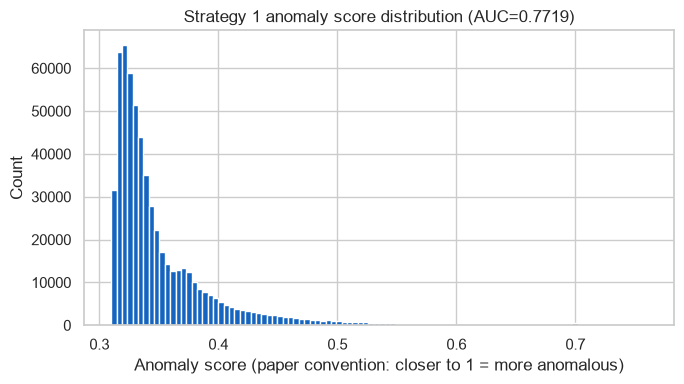

In [25]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores_s1, bins=100, color="#1565C0")
ax.set_xlabel("Anomaly score (paper convention: closer to 1 = more anomalous)")
ax.set_ylabel("Count")
ax.set_title(f"Strategy 1 anomaly score distribution (AUC={auc_s1:.4f})")
plt.tight_layout()
plt.show()


**Findings:** Strategy 1 scores **AUC = 0.7719** — the highest of all three strategies,
despite being the most naive (419 features, just median imputation and ordinal
encoding, no selection at all). The anomaly score spans a wide range, [0.310, 0.760],
consistent with the model finding plenty of room to separate unusual points. Feeding in
every available dimension doesn't seem to hurt Isolation Forest here: because each tree
only needs an occasional useful split, more raw dimensions increase the odds that an
anomaly stands out on *some* axis, even if most of the 419 columns individually carry
little signal. This is a notably better result than the original heavily-engineered
baseline (~0.72-0.73 AUC), achieved with far less preprocessing effort.


## Strategy 2: Categorical Features Only (One-Hot Encoded)

Part 1 §4 showed some categories (`ProductCD == C`, `card4 == discover`,
`card6 == credit`) have a meaningfully higher fraud rate than the dataset average. This
strategy tests whether categorical information *alone* — with no numeric features at
all — is enough for Isolation Forest to rank fraud highly.

This uses the dataset's true categorical (text/object-dtype) columns, one-hot encoded.
High-cardinality text columns (`DeviceInfo` with ~1,800 unique values, email domains,
browser/OS/resolution strings) are excluded from one-hot encoding — one-hot blows up to
one column per category, which is a scale problem one-hot isn't suited for, not a
feature-reduction decision. Categorical columns with at most 15 unique values are kept.


In [26]:
MAX_ONEHOT_CARDINALITY = 15
categorical_cols_all = [c for c in work.columns if not pd.api.types.is_numeric_dtype(work[c])]
categorical_cols_s2 = [c for c in categorical_cols_all
                        if work[c].nunique(dropna=True) <= MAX_ONEHOT_CARDINALITY]
excluded_high_card = sorted(set(categorical_cols_all) - set(categorical_cols_s2))

print(f"Categorical columns available: {len(categorical_cols_all)}")
print(f"Kept for one-hot (<= {MAX_ONEHOT_CARDINALITY} categories): {len(categorical_cols_s2)}")
print(f"Excluded (too high cardinality for one-hot): {excluded_high_card}")


Categorical columns available: 29
Kept for one-hot (<= 15 categories): 23
Excluded (too high cardinality for one-hot): ['DeviceInfo', 'P_emaildomain', 'R_emaildomain', 'id_30', 'id_31', 'id_33']


In [27]:
cat_part_s2 = work[categorical_cols_s2].fillna("missing")
X2 = pd.get_dummies(cat_part_s2, prefix=categorical_cols_s2, dtype=float)

assert X2.isna().sum().sum() == 0
print(f"Strategy 2 feature matrix: {X2.shape} "
      f"(one-hot columns from {len(categorical_cols_s2)} categorical features)")


Strategy 2 feature matrix: (590540, 79) (one-hot columns from 23 categorical features)


In [28]:
model_s2 = IsolationForest(random_state=RNG_SEED)
model_s2.fit(X2.loc[train_idx])

scores_s2 = paper_anomaly_score(model_s2, X2)
auc_s2 = roc_auc_score(y, scores_s2)
print(f"Strategy 2 -- features: {X2.shape[1]}, AUC: {auc_s2:.4f}")
print(f"Anomaly score range: [{scores_s2.min():.3f}, {scores_s2.max():.3f}]")


Strategy 2 -- features: 79, AUC: 0.6732
Anomaly score range: [0.404, 0.676]


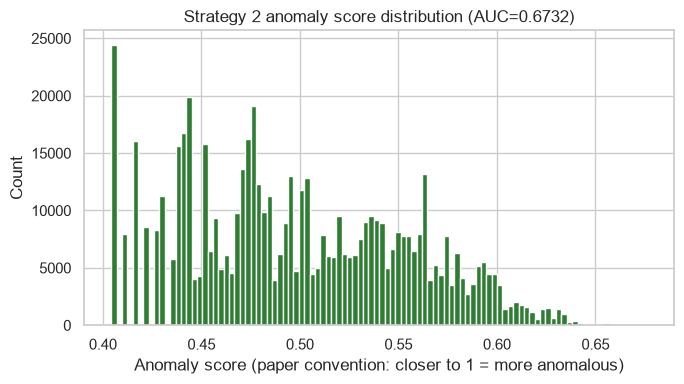

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores_s2, bins=100, color="#2E7D32")
ax.set_xlabel("Anomaly score (paper convention: closer to 1 = more anomalous)")
ax.set_ylabel("Count")
ax.set_title(f"Strategy 2 anomaly score distribution (AUC={auc_s2:.4f})")
plt.tight_layout()
plt.show()


**Findings:** Strategy 2 scores **AUC = 0.6732** — clearly the weakest of the three,
roughly 10 points of AUC below Strategy 1, though still well above random guessing
(0.5). This is despite using exactly the categories (`ProductCD`, `card4`, `card6`,
etc.) that Part 1 §4 showed have elevated fraud rates. The anomaly score range is also
the narrowest of the three, [0.404, 0.676] — one-hot categorical columns are all 0/1,
so there's a hard ceiling on how "extreme" any single point can look, which caps how
far Isolation Forest can separate anomalies. The takeaway: categorical rarity alone
*is* a real signal (the AUC is well above 0.5), but it isn't sufficient by itself —
numeric magnitude and spread information (amounts, the `V` features) is doing real
work in the other two strategies that pure categorical structure can't replace.


## Strategy 3: Correlation-Based Reduction Across V/C/D/M/id_ Features

From the engineered feature families — `V1`-`V339`, `C1`-`C14`, `D1`-`D15`, `M1`-`M9`,
and `id_01`-`id_38` — keep only the columns most correlated with `isFraud`, following
the same EDA-only correlation approach as Part 1 §6. `M` columns (`T`/`F`) are mapped
to `1`/`0`; categorical `id_` columns are label-encoded, purely so a Pearson
correlation can be computed — this is still an EDA-only use of the label to pick
features, never training on the label itself.

This cell ranks all candidate columns by |correlation with `isFraud`|; the next section tests how many of the top-ranked columns to keep.

In [30]:
vcdm_id_cols = [c for c in work.columns if re.fullmatch(r"V\d+", c)
                 or re.fullmatch(r"C\d+", c)
                 or re.fullmatch(r"D\d+", c)
                 or re.fullmatch(r"M\d+", c)
                 or re.fullmatch(r"id_\d+", c)]
print(f"V/C/D/M/id_ columns available after missing-value drop: {len(vcdm_id_cols)}")


V/C/D/M/id_ columns available after missing-value drop: 404


In [31]:
numeric_for_corr = pd.DataFrame(index=work.index)
for col in vcdm_id_cols:
    s = work[col]
    if pd.api.types.is_numeric_dtype(s):
        numeric_for_corr[col] = s.fillna(s.median())
    elif col.startswith("M") and set(s.dropna().unique()) <= {"T", "F"}:
        encoded = s.map({"T": 1, "F": 0})
        numeric_for_corr[col] = encoded.fillna(encoded.median())
    else:  # categorical id_ columns, plus M4 (values M0/M1/M2, not T/F)
        numeric_for_corr[col] = pd.factorize(s.fillna("missing"))[0]

# EDA-only use of the label to rank features -- never fed into training itself.
fraud_corr_s3 = numeric_for_corr.corrwith(y)
fraud_corr_s3 = fraud_corr_s3.reindex(fraud_corr_s3.abs().sort_values(ascending=False).index)

fraud_corr_s3.head(15)

/var/folders/t2/5njzmgsx4q17p9zt_rp8z2f80000gn/T/ipykernel_40367/443389881.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  numeric_for_corr[col] = s.fillna(s.median())
/var/folders/t2/5njzmgsx4q17p9zt_rp8z2f80000gn/T/ipykernel_40367/443389881.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  numeric_for_corr[col] = s.fillna(s.median())
/var/folders/t2/5njzmgsx4q17p9zt_rp8z2f80000gn/T/ipykernel_40367/443389881.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

V257    0.280214
V246    0.268090
V244    0.265712
V242    0.263476
V201    0.246462
V200    0.238290
V45     0.235436
V189    0.225829
V86     0.222343
V87     0.221568
V258    0.220304
V188    0.219590
V44     0.217870
V228    0.207138
V170    0.203019
dtype: float64

### Choosing top-K

The ranking above orders all 404 candidate columns by |correlation with `isFraud`|. How
many of them should Strategy 3 keep? Test K in 32, 64, 128, 256 and 404 (404 = every
eligible column, i.e. no selection at all). Each K is fit on the same fixed n=256
training sample; because a single seed is noisy at this sample size, each K is fit with
5 different `random_state` values and compared on mean AUC (seed `RNG_SEED` alone is
also shown, since that is what the strategy comparison uses).

In [32]:
TOP_K_GRID = [32, 64, 128, 256, 404]
N_SEEDS_K = 5

k_rows = []
for k in TOP_K_GRID:
    cols_k = fraud_corr_s3.head(k).index.tolist()
    Xk = numeric_for_corr[cols_k]
    aucs = []
    for seed in range(N_SEEDS_K):
        m = IsolationForest(random_state=RNG_SEED + seed)
        m.fit(Xk.loc[train_idx])
        aucs.append(roc_auc_score(y, paper_anomaly_score(m, Xk)))
    k_rows.append({
        "top_k": k,
        "auc_seed42": aucs[0],
        "auc_mean": np.mean(aucs),
        "auc_std": np.std(aucs, ddof=1),
        "min_abs_corr": fraud_corr_s3.head(k).abs().min(),
    })

topk_df = pd.DataFrame(k_rows)
topk_df

,top_k,auc_seed42,auc_mean,auc_std,min_abs_corr
0,32,0.723304,0.723188,0.000737,0.158933
1,64,0.725108,0.725037,0.001063,0.132921
2,128,0.709270,0.707318,0.001903,0.079090
3,256,0.743600,0.746798,0.003320,0.018797
4,404,0.766530,0.765205,0.007038,0.000047


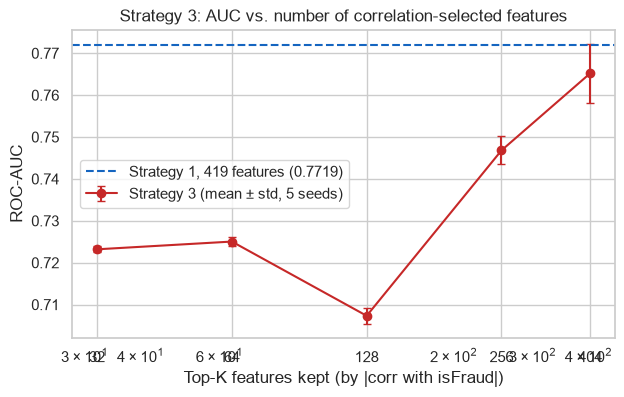

In [33]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(topk_df["top_k"], topk_df["auc_mean"], yerr=topk_df["auc_std"], marker="o",
            capsize=3, color="#C62828", label="Strategy 3 (mean ± std, 5 seeds)")
ax.axhline(auc_s1, color="#1565C0", linestyle="--", label=f"Strategy 1, 419 features ({auc_s1:.4f})")
ax.set_xscale("log")
ax.set_xticks(TOP_K_GRID)
ax.set_xticklabels(TOP_K_GRID)
ax.set_xlabel("Top-K features kept (by |corr with isFraud|)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Strategy 3: AUC vs. number of correlation-selected features")
ax.legend()
plt.show()

In [34]:
TOP_K_S3 = int(topk_df.loc[topk_df["auc_mean"].idxmax(), "top_k"])  # best mean AUC
top_cols_s3 = fraud_corr_s3.head(TOP_K_S3).index.tolist()
print(f"Selected TOP_K_S3 = {TOP_K_S3}")

Selected TOP_K_S3 = 404


In [35]:
X3 = numeric_for_corr[top_cols_s3]

assert X3.isna().sum().sum() == 0
print(f"Strategy 3 feature matrix: {X3.shape}")


Strategy 3 feature matrix: (590540, 404)


In [36]:
model_s3 = IsolationForest(random_state=RNG_SEED)
model_s3.fit(X3.loc[train_idx])

scores_s3 = paper_anomaly_score(model_s3, X3)
auc_s3 = roc_auc_score(y, scores_s3)
print(f"Strategy 3 -- features: {X3.shape[1]}, AUC: {auc_s3:.4f}")
print(f"Anomaly score range: [{scores_s3.min():.3f}, {scores_s3.max():.3f}]")


Strategy 3 -- features: 404, AUC: 0.7665
Anomaly score range: [0.306, 0.769]


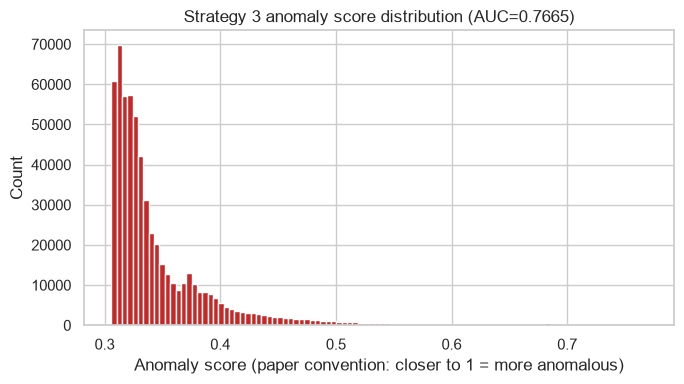

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores_s3, bins=100, color="#C62828")
ax.set_xlabel("Anomaly score (paper convention: closer to 1 = more anomalous)")
ax.set_ylabel("Count")
ax.set_title(f"Strategy 3 anomaly score distribution (AUC={auc_s3:.4f})")
plt.tight_layout()
plt.show()


**Findings:** the top-K sweep (see the table and plot above) shows that **picking fewer columns by correlation with `isFraud` makes Strategy 3 worse, not better**. Mean AUC over 5 seeds is 0.7232 at K=32, 0.7250 at K=64, 0.7073 at K=128, 0.7468 at K=256 and **0.7652 at K=404**, i.e. every eligible `V`/`C`/`D`/`M`/`id_` column. **K=404 is the best-performing number and is used for Strategy 3 and Strategy 4**; its AUC with the standard `RNG_SEED` is **0.7665**.

## Strategy 4: Categorical + Correlation-Reduced Numeric Combined

Strategies 2 and 3 captured different kinds of signal — categorical rarity (one-hot, 79 columns) and the numeric engineered features (`V`/`C`/`D`/`M`/`id_`) — and the full-feature Strategy 1 was the best result so far. This strategy tests whether the two are complementary: simply concatenate Strategy 2's one-hot matrix and Strategy 3's matrix into one feature set and fit Isolation Forest on the combination, using the same fixed n=256 training sample as every other strategy.

Strategy 3's top-K was chosen by the sweep in Strategy 3 above: **K=404 performed best, so Strategy 4 uses all 404 `V`/`C`/`D`/`M`/`id_` columns** (`TOP_K_S3`).

In [38]:
X4 = pd.concat([X2, X3], axis=1)

assert X4.isna().sum().sum() == 0
print(f"Strategy 4 feature matrix: {X4.shape} "
      f"(Strategy 2's {X2.shape[1]} one-hot + Strategy 3's {X3.shape[1]} correlation-selected)")


Strategy 4 feature matrix: (590540, 483) (Strategy 2's 79 one-hot + Strategy 3's 404 correlation-selected)


In [39]:
model_s4 = IsolationForest(random_state=RNG_SEED)
model_s4.fit(X4.loc[train_idx])

scores_s4 = paper_anomaly_score(model_s4, X4)
auc_s4 = roc_auc_score(y, scores_s4)
print(f"Strategy 4 -- features: {X4.shape[1]}, AUC: {auc_s4:.4f}")
print(f"Anomaly score range: [{scores_s4.min():.3f}, {scores_s4.max():.3f}]")


Strategy 4 -- features: 483, AUC: 0.7739
Anomaly score range: [0.323, 0.762]


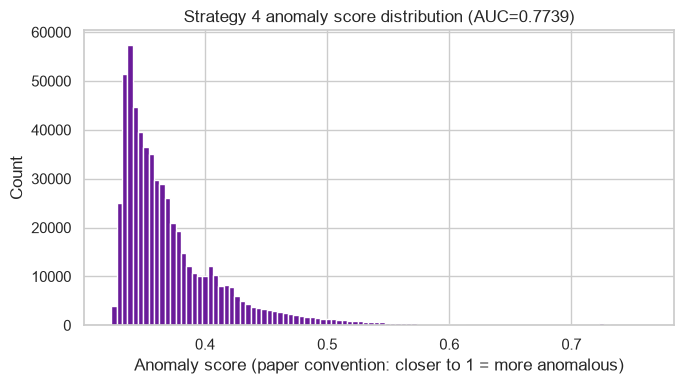

In [40]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores_s4, bins=100, color="#6A1B9A")
ax.set_xlabel("Anomaly score (paper convention: closer to 1 = more anomalous)")
ax.set_ylabel("Count")
ax.set_title(f"Strategy 4 anomaly score distribution (AUC={auc_s4:.4f})")
plt.tight_layout()
plt.show()


**Findings:** Strategy 4 scores **AUC = 0.7739** with **483 features** (79 one-hot + 404 numeric) — the highest AUC of the four strategies, though only by 0.002 over Strategy 1 (0.7719), which is within the seed-to-seed noise seen in the Strategy 3 sweep (std up to 0.007), so the honest reading is that Strategy 4 *matches* Strategy 1 rather than clearly beating it. It does clearly beat both of its ingredients: Strategy 2 (0.6732) by a wide margin, and Strategy 3 at the same K (0.7665) by about 0.7 points, so the one-hot categoricals add a small amount of complementary signal on top of the numeric block. The score range, [0.323, 0.762], is close to Strategy 1's [0.310, 0.760].

## Strategy Comparison

In [41]:
comparison = pd.DataFrame({
    "strategy": ["1: Full high-dim (no reduction)", "2: Categorical only (one-hot)",
                 "3: Correlation-reduced V/C/D/M/id_", "4: Categorical + correlation combined"],
    "n_features": [X1.shape[1], X2.shape[1], X3.shape[1], X4.shape[1]],
    "auc": [auc_s1, auc_s2, auc_s3, auc_s4],
})
comparison


,strategy,n_features,auc
0,1: Full high-dim (no reduction),419,0.771877
1,2: Categorical only (one-hot),79,0.673170
2,3: Correlation-reduced V/C/D/M/id_,404,0.766530
3,4: Categorical + correlation combined,483,0.773880


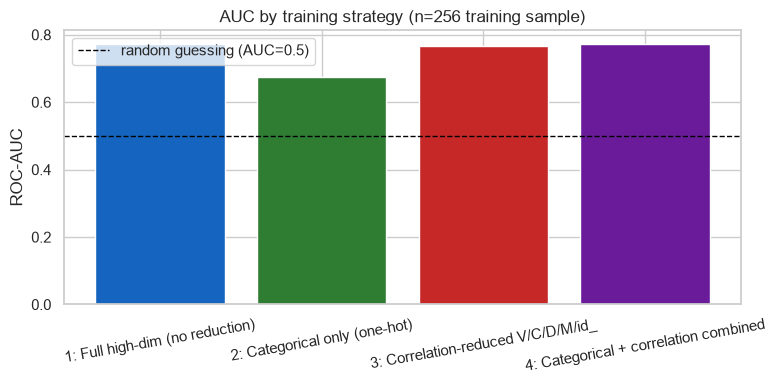

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#1565C0", "#2E7D32", "#C62828", "#6A1B9A"]
ax.bar(comparison["strategy"], comparison["auc"], color=colors)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1, label="random guessing (AUC=0.5)")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"AUC by training strategy (n={TRAIN_SAMPLE_SIZE} training sample)")
ax.tick_params(axis="x", rotation=10)
ax.legend()
plt.tight_layout()
plt.show()


**Findings:** ranked by AUC — **Strategy 4 (0.7739, 483 features) ≳ Strategy 1 (0.7719, 419 features) > Strategy 3 (0.7665, 404 features) > Strategy 2 (0.6732, 79 features)**. The three strategies that use the numeric engineered features are all within about 0.8 points of each other, and the Strategy 4 vs. Strategy 1 gap (0.002) is inside seed noise. What clearly separates the strategies is whether the numeric `V`/`C`/`D`/`M`/`id_` block is included at all: Strategy 2 (categoricals only) is ~9 points behind, while adding the categoricals on top of the numeric block (Strategy 4 vs. Strategy 3) gives a smaller gain of about 0.7 points. The conclusion that supports the rest of this notebook: for Isolation Forest, keeping many features beat correlation-based pruning here, and Strategy 1 remains the simplest baseline of equivalent quality (it is the one used in Parts 3 and 4).

# Part 3: Deeper Look at the Baseline -- Strategy 1


## Anomaly Score Surface (UMAP Layout, Full 419-Feature Score)

Steps:

1. Draw a random subsample for visualization
2. Standardize, then pre-reduce with PCA to 50 components — UMAP's own documentation
   recommends this for very high-dimensional input, both for speed and because UMAP's
   nearest-neighbor search is more reliable in a less noisy, lower-dimensional space.
3. Fit UMAP on those 50 components to get a 2D layout.
4. Plot a hexbin surface (mean real anomaly score per hexagon) with KDE density
   contour lines on top (showing where the data actually concentrates), and the
   withheld fraud points marked individually.


In [43]:
N_VIZ = 30000
rng_viz = np.random.default_rng(RNG_SEED)
viz_idx = rng_viz.choice(df.index, size=N_VIZ, replace=False)

X1_scaled_viz = StandardScaler().fit_transform(X1.loc[viz_idx])
pca_pre = PCA(n_components=50, random_state=RNG_SEED)
X1_pca50 = pca_pre.fit_transform(X1_scaled_viz)
print(f"Visualization subsample: {N_VIZ:,} rows")
print(f"PCA pre-reduction: 419 -> 50 components, "
      f"explaining {pca_pre.explained_variance_ratio_.sum() * 100:.1f}% of variance")


Visualization subsample: 30,000 rows
PCA pre-reduction: 419 -> 50 components, explaining 80.9% of variance


In [44]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=RNG_SEED)
embedding = reducer.fit_transform(X1_pca50)
print(f"UMAP embedding shape: {embedding.shape}")


/Users/joyce/Desktop/FraudDetection/Unsupervised-fraud-detection-the-outliers/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding shape: (30000, 2)


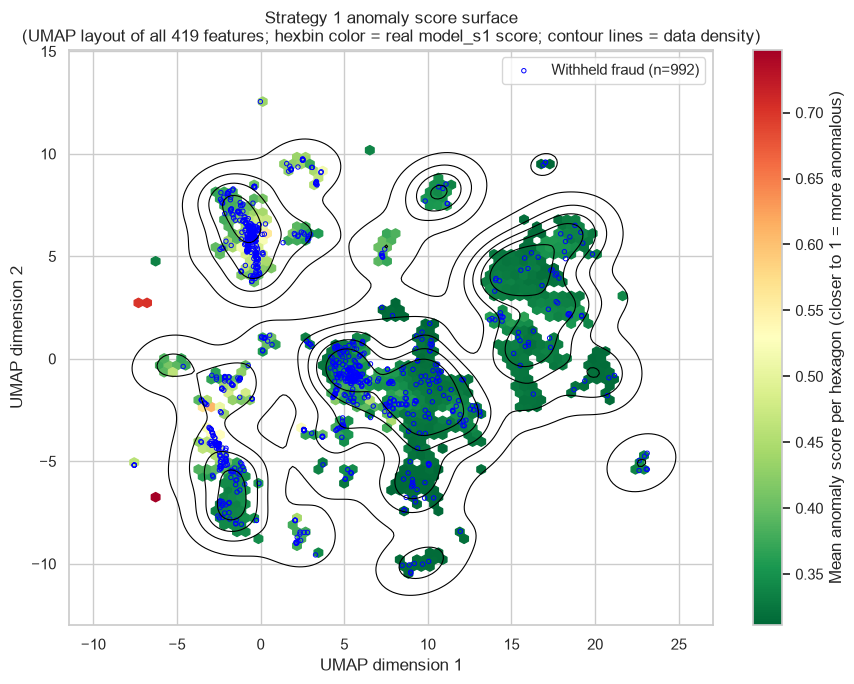

In [45]:
viz_scores = scores_s1[viz_idx]  # real Strategy 1 anomaly scores, full 419-feature model
viz_fraud = df.loc[viz_idx, "isFraud"].values

fig, ax = plt.subplots(figsize=(9, 7))
hb = ax.hexbin(embedding[:, 0], embedding[:, 1], C=viz_scores, reduce_C_function=np.mean,
               gridsize=60, cmap="RdYlGn_r", mincnt=5)
plt.colorbar(hb, ax=ax, label="Mean anomaly score per hexagon (closer to 1 = more anomalous)")

sns.kdeplot(x=embedding[:, 0], y=embedding[:, 1], levels=6, color="black", linewidths=0.8, ax=ax)

fraud_mask = viz_fraud == 1
ax.scatter(embedding[fraud_mask, 0], embedding[fraud_mask, 1], s=10, facecolors="none",
           edgecolors="blue", linewidths=0.7, label=f"Withheld fraud (n={fraud_mask.sum()})")

ax.set_xlabel("UMAP dimension 1")
ax.set_ylabel("UMAP dimension 2")
ax.set_title("Strategy 1 anomaly score surface\n"
              "(UMAP layout of all 419 features; hexbin color = real model_s1 score; "
              "contour lines = data density)")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


**Findings:**

PCA reduced the 419 features to 50 components while still keeping 80.9% of the original variance. This gives UMAP a fairly good representation of the original data instead of working with the full high-dimensional space.

UMAP shows several distinct clusters rather than one continuous cloud. The exact shapes of these clusters should not be over-interpreted, but the colors are useful because they show the actual model_s1 scores. Most of the points are green, with scores around 0.30–0.40, meaning the model sees most transactions as fairly normal. However, two small groups around (-7, 3) and (-7, -7) have much higher scores, around 0.70+. These groups are both structurally unusual in UMAP and considered unusual by the Isolation Forest, which is a good sign that the two methods are picking up similar patterns.

The 992 fraud transactions in the sample are spread across almost all of the clusters, including the large green ones. They do not mainly appear in the red outlier groups. This matches the AUC of 0.77: Isolation Forest can identify some genuinely unusual transactions, but many fraudulent transactions look similar to normal transactions in the feature space.

Overall, this shows an important limitation of using an unsupervised anomaly detection method. Fraud is not always an obvious structural outlier. Some fraud looks unusual, but a lot of it blends in with normal transactions.


## Anomaly Score Distribution and Top 10 Most Anomalous Transactions

The UMAP view above shows *where* high scores sit. This section looks at the score
distribution itself for the baseline (Strategy 1, `model_s1`), and pulls out the 10
transactions the baseline considers most anomalous.

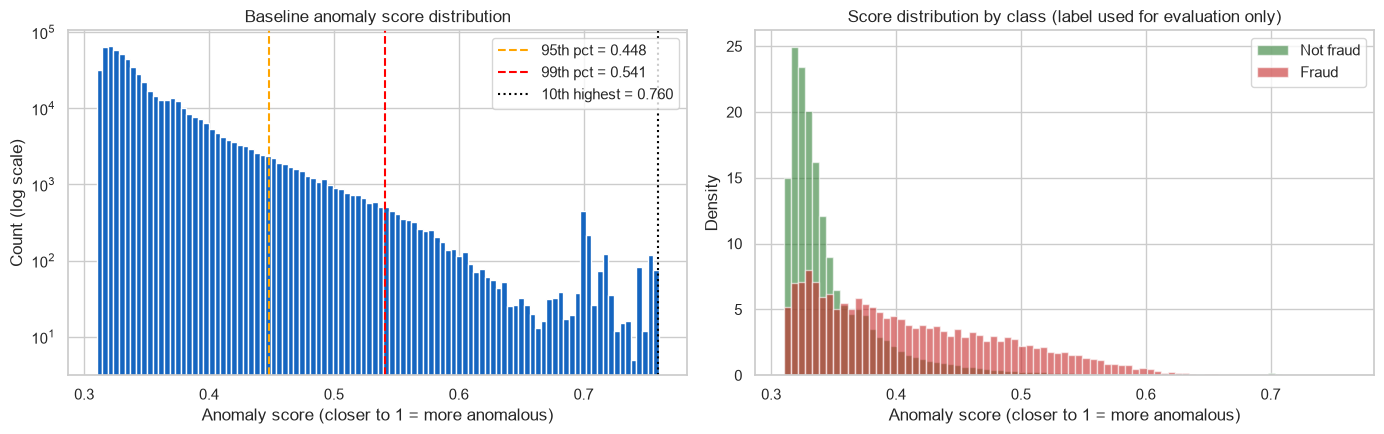

Mean score: 0.352, median: 0.335, std: 0.048
Mean score -- fraud: 0.412, non-fraud: 0.350


In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

q95, q99 = np.quantile(scores_s1, [0.95, 0.99])
top10_cutoff = np.sort(scores_s1)[-10]

# Left: overall distribution with the tail cutoffs marked
axes[0].hist(scores_s1, bins=100, color="#1565C0")
axes[0].axvline(q95, color="orange", linestyle="--", label=f"95th pct = {q95:.3f}")
axes[0].axvline(q99, color="red", linestyle="--", label=f"99th pct = {q99:.3f}")
axes[0].axvline(top10_cutoff, color="black", linestyle=":", label=f"10th highest = {top10_cutoff:.3f}")
axes[0].set_yscale("log")
axes[0].set_xlabel("Anomaly score (closer to 1 = more anomalous)")
axes[0].set_ylabel("Count (log scale)")
axes[0].set_title("Baseline anomaly score distribution")
axes[0].legend()

# Right: same scores split by the withheld label (density-normalised, since fraud is only 3.5%)
bins = np.linspace(scores_s1.min(), scores_s1.max(), 80)
axes[1].hist(scores_s1[y.values == 0], bins=bins, density=True, alpha=0.6, color="#2E7D32", label="Not fraud")
axes[1].hist(scores_s1[y.values == 1], bins=bins, density=True, alpha=0.6, color="#C62828", label="Fraud")
axes[1].set_xlabel("Anomaly score (closer to 1 = more anomalous)")
axes[1].set_ylabel("Density")
axes[1].set_title("Score distribution by class (label used for evaluation only)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Mean score: {scores_s1.mean():.3f}, median: {np.median(scores_s1):.3f}, "
      f"std: {scores_s1.std():.3f}")
print(f"Mean score -- fraud: {scores_s1[y.values == 1].mean():.3f}, "
      f"non-fraud: {scores_s1[y.values == 0].mean():.3f}")

In [47]:
top10_idx = np.argsort(scores_s1)[::-1][:10]

top10 = df.iloc[top10_idx][["TransactionID", "isFraud", "TransactionAmt", "ProductCD",
                              "card4", "card6", "P_emaildomain", "DeviceType"]].copy()
top10.insert(1, "anomaly_score", scores_s1[top10_idx])
top10 = top10.reset_index(drop=True)
top10.index = top10.index + 1  # rank 1..10
print(f"Frauds among the top 10: {int(top10['isFraud'].sum())} / 10 "
      f"(overall fraud rate is {fraud_pct:.2f}%)")
top10

Frauds among the top 10: 0 / 10 (overall fraud rate is 3.50%)


,TransactionID,anomaly_score,isFraud,TransactionAmt,ProductCD,card4,card6,P_emaildomain,DeviceType
1,3403665,0.760289,0,45.0,S,discover,credit,NaN,desktop
2,3065870,0.760021,0,1000.0,R,visa,credit,anonymous.com,desktop
3,3526266,0.759717,0,106.0,S,mastercard,credit,NaN,desktop
4,3526271,0.759717,0,106.0,S,mastercard,credit,NaN,desktop
5,3526290,0.759717,0,106.0,S,mastercard,credit,NaN,desktop
6,3526253,0.759717,0,106.0,S,mastercard,credit,NaN,desktop
7,3526307,0.759717,0,106.0,S,mastercard,credit,NaN,desktop
8,3526258,0.759717,0,106.0,S,mastercard,credit,NaN,desktop
9,3526260,0.759717,0,106.0,S,mastercard,credit,NaN,desktop
10,3526261,0.759717,0,106.0,S,mastercard,credit,NaN,desktop


In [48]:
# Why these ten? Features where each top-10 transaction sits furthest from the typical
# (median) row, in units of that column's standard deviation -- numeric columns only.
num_X1 = X1[numeric_cols_s1]
z = (num_X1.iloc[top10_idx] - num_X1.median()) / num_X1.std().replace(0, np.nan)
for rank, (row_id, row) in enumerate(z.iterrows(), start=1):
    top3 = row.abs().sort_values(ascending=False).head(3)
    desc = ", ".join(f"{c} ({row[c]:+.1f} sd)" for c in top3.index)
    print(f"#{rank:>2}  TransactionID {df.loc[row_id, 'TransactionID']}: {desc}")

# 1  TransactionID 3403665: V138 (+43.7 sd), V226 (+30.8 sd), V273 (+27.4 sd)
# 2  TransactionID 3065870: V270 (+124.1 sd), V272 (+116.6 sd), V271 (+109.6 sd)
# 3  TransactionID 3526266: V226 (+41.6 sd), V237 (+39.3 sd), V236 (+37.3 sd)
# 4  TransactionID 3526271: V226 (+43.1 sd), V237 (+39.3 sd), V236 (+37.3 sd)
# 5  TransactionID 3526290: V226 (+46.9 sd), V237 (+39.3 sd), V236 (+37.3 sd)
# 6  TransactionID 3526253: V237 (+39.3 sd), V236 (+37.3 sd), V226 (+36.2 sd)
# 7  TransactionID 3526307: V226 (+43.1 sd), V237 (+39.3 sd), V236 (+37.3 sd)
# 8  TransactionID 3526258: V237 (+39.3 sd), V236 (+37.3 sd), V226 (+36.9 sd)
# 9  TransactionID 3526260: V237 (+39.3 sd), V226 (+37.7 sd), V236 (+37.3 sd)
#10  TransactionID 3526261: V237 (+39.3 sd), V226 (+38.5 sd), V236 (+37.3 sd)


**Findings:**

The score distribution is a single large, right-skewed hump: median 0.335, mean 0.352,
std 0.048, with a thin tail running out to 0.76. The log-scale view makes that tail
visible -- very few transactions sit anywhere near the top. Splitting by the withheld
label (right panel) shows why AUC is only 0.77: fraud is shifted slightly right
(mean score 0.412 vs. 0.350 for non-fraud) but the two densities overlap heavily.

**None of the 10 most anomalous transactions is fraud** (0/10, vs. a 3.5% base rate).
What makes them anomalous is not "looks like fraud" but "is extreme on the `V`
features": the single most extreme columns are 37-47 standard deviations above the
median for 9 of them, and 110-124 sd for #2 (`V270`/`V271`/`V272`). Eight of the ten
(ranks 3-10) are near-copies of each other -- `ProductCD == S`, $106, mastercard credit,
no purchaser email, consecutive `TransactionID`s 3526253-3526307 -- i.e. one burst of
repeated identical transactions, all sharing the same extreme `V226`/`V236`/`V237`
values. So the top of the ranking is dominated by a single odd-looking cluster rather
than ten independent anomalies, and structural outlierness at the very top of the list
is not a reliable fraud signal. This matches the UMAP view, where the highest-scoring
groups were small isolated clusters that did not contain the fraud points.

# Part 4: Fine-tuning the Baseline

# Sample-Size

Strategies 1-4 were all trained at a fixed n=256 for a fair comparison between feature
sets. This section asks a different question for Strategy 1 specifically (the
best-performing feature set): **how do AUC and computation time change with the
training sample size**, and what's the best size to use?

**Setup**

- Sample sizes: powers of 4, from `4` up through the full dataset (`4, 16, 64, 256,
  1,024, 4,096, 16,384, 65,536, 262,144`, then the full 590,540 rows).
- Each size is fit 3 times (random `IsolationForest(random_state=RNG_SEED + repeat)`,
  a fresh random training subsample each repeat) and timing is reported as mean ± std,
  since timing has run-to-run noise.
- Every fit uses Strategy 1's feature matrix `X1` and is scored against the full
  dataset (`X1`, `y`) — same evaluation convention as Strategies 1-4, no held-out split.
- AUC and (fit + score) time are plotted together on one chart, sample size on a log
  x-axis, with AUC on a linear left axis and time on a log right axis (time spans
  several orders of magnitude across this range; AUC doesn't).


## Benchmark

In [49]:
sizes = []
s = 4
while s < len(df):
    sizes.append(s)
    s *= 4
sizes.append(len(df))
N_REPEATS = 3
print(f"Sample sizes (powers of 4, capped at the full dataset): {sizes}")


Sample sizes (powers of 4, capped at the full dataset): [4, 16, 64, 256, 1024, 4096, 16384, 65536, 262144, 590540]


In [50]:
results = []
rng_scale = np.random.default_rng(RNG_SEED)

for size in sizes:
    for repeat in range(N_REPEATS):
        sample_idx = rng_scale.choice(df.index, size=size, replace=False)
        X_train = X1.loc[sample_idx]

        t0 = time.perf_counter()
        model = IsolationForest(random_state=RNG_SEED + repeat)
        model.fit(X_train)
        fit_time = time.perf_counter() - t0

        t0 = time.perf_counter()
        scores = paper_anomaly_score(model, X1)
        score_time = time.perf_counter() - t0

        auc = roc_auc_score(y, scores)
        results.append({"size": size, "repeat": repeat, "fit_time": fit_time,
                         "score_time": score_time, "total_time": fit_time + score_time,
                         "auc": auc})

results_df = pd.DataFrame(results)
summary = results_df.groupby("size").agg(
    auc_mean=("auc", "mean"), auc_std=("auc", "std"),
    fit_time_mean=("fit_time", "mean"), fit_time_std=("fit_time", "std"),
    total_time_mean=("total_time", "mean"), total_time_std=("total_time", "std"),
).reset_index()
summary


,size,auc_mean,auc_std,fit_time_mean,fit_time_std,total_time_mean,total_time_std
0,4,0.620870,0.123354,0.081024,0.001876,2.813557,0.245047
1,16,0.732311,0.011260,0.080950,0.001698,3.176259,0.203537
2,64,0.760997,0.007898,0.082144,0.001608,3.322810,0.068900
3,256,0.762780,0.005470,0.085100,0.001362,3.772031,0.188497
4,1024,0.766091,0.005426,0.088325,0.001240,3.455951,0.030657
5,4096,0.764616,0.002577,0.097283,0.000302,3.440094,0.100639
6,16384,0.768291,0.003747,0.137848,0.003359,3.490649,0.076148
7,65536,0.769147,0.005058,0.220867,0.006802,3.720527,0.080498
8,262144,0.765025,0.003451,1.144400,0.086543,4.703909,0.069589
9,590540,0.766688,0.003952,2.771173,0.221195,6.834294,0.326370


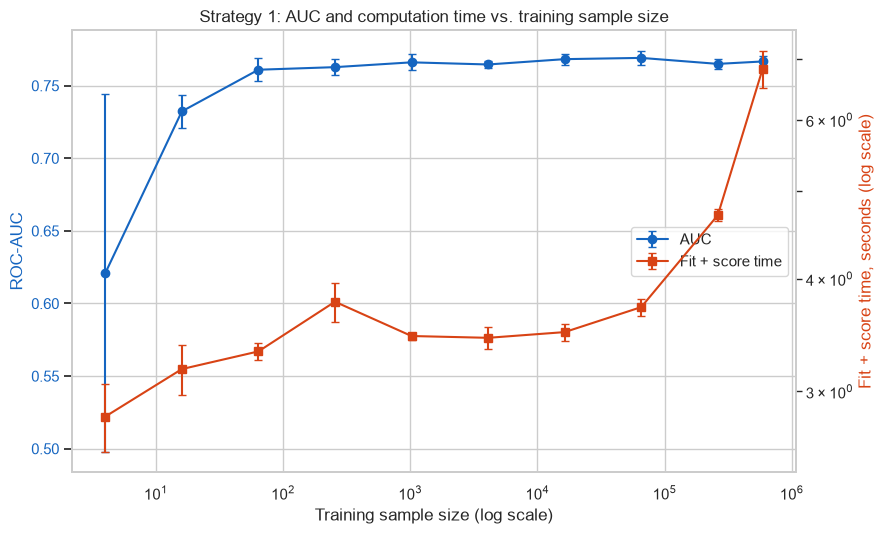

In [51]:
fig, ax1 = plt.subplots(figsize=(9, 5.5))

ax1.errorbar(summary["size"], summary["auc_mean"], yerr=summary["auc_std"],
             marker="o", color="#1565C0", capsize=3, label="AUC")
ax1.set_xscale("log")
ax1.set_xlabel("Training sample size (log scale)")
ax1.set_ylabel("ROC-AUC", color="#1565C0")
ax1.tick_params(axis="y", labelcolor="#1565C0")

ax2 = ax1.twinx()
ax2.errorbar(summary["size"], summary["total_time_mean"], yerr=summary["total_time_std"],
             marker="s", color="#D84315", capsize=3, label="Fit + score time")
ax2.set_yscale("log")
ax2.set_ylabel("Fit + score time, seconds (log scale)", color="#D84315")
ax2.tick_params(axis="y", labelcolor="#D84315")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")

ax1.set_title("Strategy 1: AUC and computation time vs. training sample size")
plt.tight_layout()
plt.show()


## Identifying the Best Sample Size

Rule: find the best AUC observed across all sizes, then pick the **smallest** sample
size whose AUC is within 1% of that best — i.e. the point where growing the sample
stops meaningfully improving AUC but keeps costing more time.


In [52]:
AUC_TOLERANCE = 0.99  # "as good as the best" = within 1% of the best observed AUC

max_row = summary.loc[summary["auc_mean"].idxmax()]
best_auc = max_row["auc_mean"]

qualifying = summary[summary["auc_mean"] >= best_auc * AUC_TOLERANCE]
best_size = int(qualifying["size"].min())
best_row = summary[summary["size"] == best_size].iloc[0]
full_row = summary[summary["size"] == len(df)].iloc[0]

print(f"Best AUC observed: {best_auc:.4f} at size {int(max_row['size']):,} "
      f"(fit+score time={max_row['total_time_mean']:.3f}s)")
print(f"Smallest size within {(1 - AUC_TOLERANCE) * 100:.0f}% of best AUC: "
      f"{best_size:,} (AUC={best_row['auc_mean']:.4f}, "
      f"fit+score time={best_row['total_time_mean']:.3f}s)")
print(f"Full-size ({len(df):,}) fit+score time for comparison: "
      f"{full_row['total_time_mean']:.3f}s")
print(f"Speedup at best_size vs. full size: "
      f"{full_row['total_time_mean'] / best_row['total_time_mean']:.1f}x")


Best AUC observed: 0.7691 at size 65,536 (fit+score time=3.721s)
Smallest size within 1% of best AUC: 256 (AUC=0.7628, fit+score time=3.772s)
Full-size (590,540) fit+score time for comparison: 6.834s
Speedup at best_size vs. full size: 1.8x


**Findings:** AUC rises sharply and noisily at the smallest sizes — n=4 averages just
0.621 with a huge std (±0.123, meaning individual repeats swing wildly depending on
which 4 rows get sampled) — then climbs through n=16 (0.732) and n=64 (0.761), and from
n=64 onward it's essentially flat, oscillating in a tight 0.763-0.769 band all the way
to the full dataset (0.767). The peak mean AUC (0.7691) happens at n=65,536, but that's
within noise of several smaller sizes, not a real peak. The **1%-tolerance rule picks
`best_size = 256`** — which happens to be exactly the training size used for Strategies
1-4 throughout this notebook, a nice independent confirmation that n=256 wasn't an
arbitrary choice.


## Contamination

`contamination` is the expected fraction of anomalies. In scikit-learn it does **not**
change how the trees are built or how any transaction is scored -- it only sets
`offset_`, the score cutoff above which `predict` flags a transaction. So the ranking
(and therefore AUC) should be identical across values; what should change is *how many*
transactions end up flagged.

Values tried: 0.01, 0.02, 0.035 (roughly the true fraud rate), 0.05, 0.10. Every model
uses the same fixed n=256 training sample and `random_state` as the baseline.

In [53]:
CONTAMINATIONS = [0.01, 0.02, 0.035, 0.05, 0.10]

cont_rows = []
cont_scores = {}
for c in CONTAMINATIONS:
    m = IsolationForest(contamination=c, random_state=RNG_SEED)
    m.fit(X1.loc[train_idx])
    s = paper_anomaly_score(m, X1)
    cont_scores[c] = s
    flagged = m.predict(X1) == -1
    tp = int((flagged & (y.values == 1)).sum())
    cont_rows.append({
        "contamination": c,
        "score_threshold": -m.offset_,
        "n_flagged": int(flagged.sum()),
        "pct_flagged": flagged.mean() * 100,
        "true_frauds_caught": tp,
        "precision": tp / max(flagged.sum(), 1),
        "recall": tp / y.sum(),
        "auc": roc_auc_score(y, s),
        "max_score_diff_vs_baseline": np.abs(s - scores_s1).max(),
    })

cont_df = pd.DataFrame(cont_rows)
cont_df

,contamination,score_threshold,n_flagged,pct_flagged,true_frauds_caught,precision,recall,auc,max_score_diff_vs_baseline
0,0.010,0.561283,4059,0.687337,865,0.213107,0.041862,0.771877,0.0
1,0.020,0.536542,6419,1.086971,1592,0.248014,0.077046,0.771877,0.0
2,0.035,0.489416,14714,2.491618,3696,0.251189,0.178870,0.771877,0.0
3,0.050,0.457699,25111,4.252210,5595,0.222811,0.270774,0.771877,0.0
4,0.100,0.414279,52520,8.893555,8681,0.165289,0.420123,0.771877,0.0


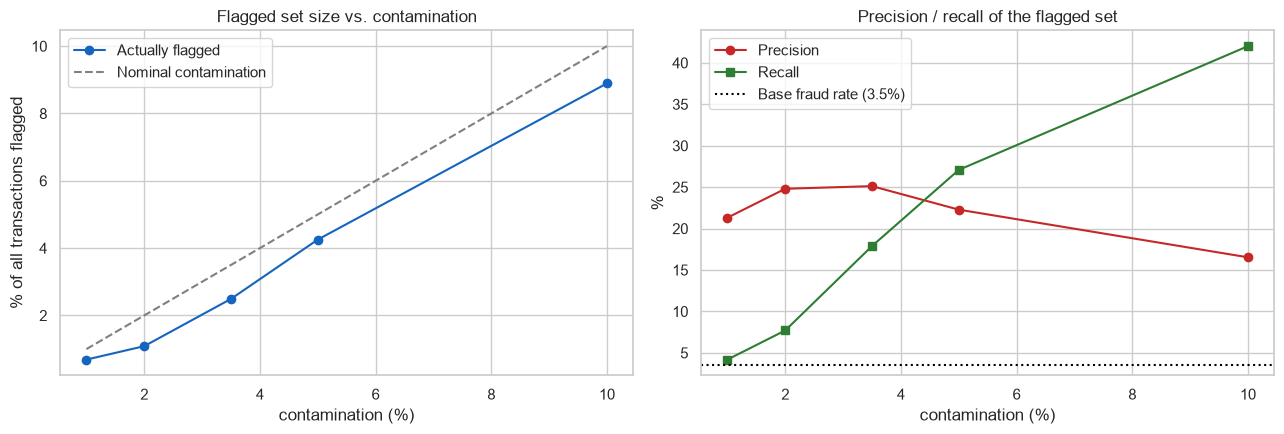

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(cont_df["contamination"] * 100, cont_df["pct_flagged"], marker="o", color="#1565C0",
             label="Actually flagged")
axes[0].plot(cont_df["contamination"] * 100, cont_df["contamination"] * 100, linestyle="--",
             color="gray", label="Nominal contamination")
axes[0].set_xlabel("contamination (%)")
axes[0].set_ylabel("% of all transactions flagged")
axes[0].set_title("Flagged set size vs. contamination")
axes[0].legend()

axes[1].plot(cont_df["contamination"] * 100, cont_df["precision"] * 100, marker="o", color="#C62828",
             label="Precision")
axes[1].plot(cont_df["contamination"] * 100, cont_df["recall"] * 100, marker="s", color="#2E7D32",
             label="Recall")
axes[1].axhline(fraud_pct, color="black", linestyle=":", label=f"Base fraud rate ({fraud_pct:.1f}%)")
axes[1].set_xlabel("contamination (%)")
axes[1].set_ylabel("%")
axes[1].set_title("Precision / recall of the flagged set")
axes[1].legend()

plt.tight_layout()
plt.show()

**Findings:** as expected, contamination does nothing to the ranking: AUC is
0.7719 for every value and the maximum score difference vs. the baseline is exactly 0.
It only moves the cutoff, and the flagged set responds strongly:

| contamination | flagged | % of data | frauds caught | precision | recall |
|---|---|---|---|---|---|
| 0.010 | 4,059 | 0.69% | 865 | 21.3% | 4.2% |
| 0.020 | 6,419 | 1.09% | 1,592 | 24.8% | 7.7% |
| 0.035 | 14,714 | 2.49% | 3,696 | 25.1% | 17.9% |
| 0.050 | 25,111 | 4.25% | 5,595 | 22.3% | 27.1% |
| 0.100 | 52,520 | 8.89% | 8,681 | 16.5% | 42.0% |

Two things worth noting. First, the share of transactions actually flagged is *lower*
than the nominal contamination at every setting (e.g. 2.49% at 0.035, 8.9% at 0.10):
scikit-learn sets the threshold as that percentile of the scores of the 256 *training*
rows, and those 256 rows don't have exactly the same score distribution as the full
590k, so the nominal value is only a rough guide to the flagged fraction. Second, it is
a straightforward precision/recall trade: recall climbs from 4% to 42% as the flagged
set grows ~13x, while precision peaks around the true fraud rate (0.035, 25.1% --
about 7x the 3.5% base rate) and then falls as more normal transactions are swept in.
Choosing contamination is a business decision about review capacity, not a way to
improve the model.

## n_estimators

Here the training sample is held fixed (the same 256 rows) and only the forest changes,
so any difference between runs is purely tree randomness. For each of
`n_estimators` in 50, 100, 200, 500 the forest is fit with 5 different `random_state`
values, and every pair of seeds is compared on how similarly they rank all 590,540
transactions:

- **Spearman rank correlation** between the two score vectors (1.0 = identical ranking).
- **Top-1% overlap** -- Jaccard overlap of the two sets of the 5,905 highest-scoring
  transactions (1.0 = identical flagged set).
- **AUC** mean ± std across the 5 seeds.

In [55]:
from itertools import combinations

N_ESTIMATORS_GRID = [50, 100, 200, 500]
N_SEEDS = 5
TOP_FRAC = 0.01
k_top = int(len(df) * TOP_FRAC)

nest_rows = []
nest_scores = {}  # (n_estimators, seed) -> score vector, kept for the plot below
for n_est in N_ESTIMATORS_GRID:
    ranks, top_sets, aucs = [], [], []
    t0 = time.perf_counter()
    for seed in range(N_SEEDS):
        m = IsolationForest(n_estimators=n_est, random_state=RNG_SEED + seed, n_jobs=-1)
        m.fit(X1.loc[train_idx])
        s = paper_anomaly_score(m, X1)
        nest_scores[(n_est, seed)] = s
        aucs.append(roc_auc_score(y, s))
        ranks.append(pd.Series(s).rank().values)
        top_sets.append(set(np.argpartition(s, -k_top)[-k_top:]))
    elapsed = time.perf_counter() - t0

    spearman = [np.corrcoef(a, b)[0, 1] for a, b in combinations(ranks, 2)]
    jaccard = [len(a & b) / len(a | b) for a, b in combinations(top_sets, 2)]
    nest_rows.append({
        "n_estimators": n_est,
        "auc_mean": np.mean(aucs), "auc_std": np.std(aucs, ddof=1),
        "spearman_between_seeds": np.mean(spearman),
        "top1pct_overlap_between_seeds": np.mean(jaccard),
        "time_per_fit+score_s": elapsed / N_SEEDS,
    })

nest_df = pd.DataFrame(nest_rows)
nest_df

,n_estimators,auc_mean,auc_std,spearman_between_seeds,top1pct_overlap_between_seeds,time_per_fit+score_s
0,50,0.764501,0.004455,0.902188,0.616807,3.212749
1,100,0.768162,0.004027,0.949771,0.717384,4.023274
2,200,0.769243,0.002647,0.973269,0.791332,5.815427
3,500,0.770200,0.001912,0.987196,0.855585,10.962016


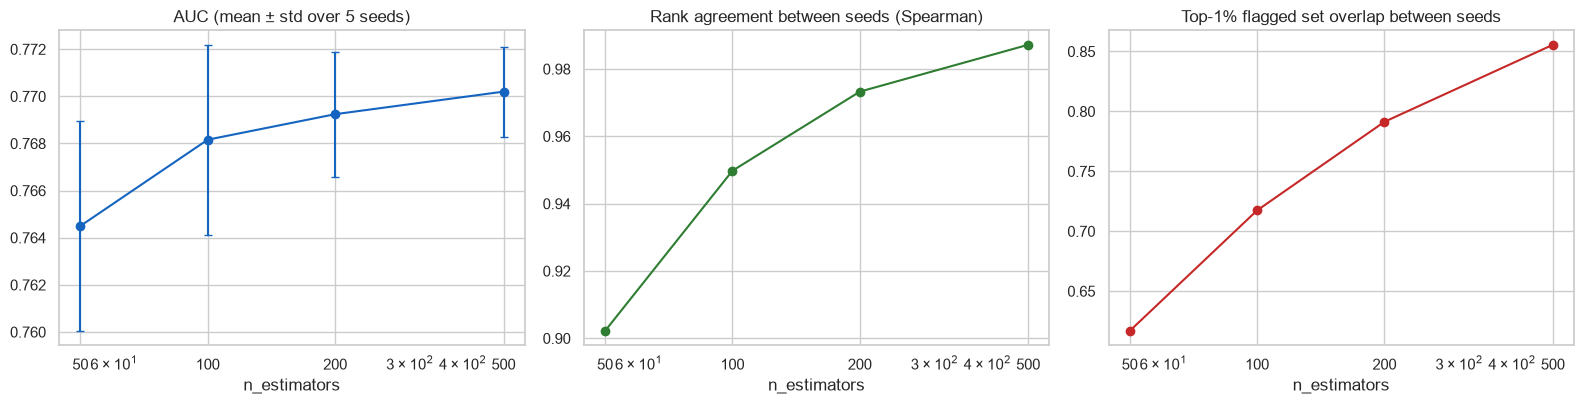

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].errorbar(nest_df["n_estimators"], nest_df["auc_mean"], yerr=nest_df["auc_std"],
                 marker="o", capsize=3, color="#1565C0")
axes[0].set_title("AUC (mean ± std over 5 seeds)")

axes[1].plot(nest_df["n_estimators"], nest_df["spearman_between_seeds"], marker="o", color="#2E7D32")
axes[1].set_title("Rank agreement between seeds (Spearman)")

axes[2].plot(nest_df["n_estimators"], nest_df["top1pct_overlap_between_seeds"], marker="o", color="#C62828")
axes[2].set_title("Top-1% flagged set overlap between seeds")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(N_ESTIMATORS_GRID)
    ax.set_xticklabels(N_ESTIMATORS_GRID)
    ax.set_xlabel("n_estimators")
plt.tight_layout()
plt.show()

**Findings:** more trees steadily make the model more *repeatable*, with
diminishing returns, but they barely change how *good* it is:

| n_estimators | AUC (mean ± std) | Spearman between seeds | top-1% overlap | time / fit+score |
|---|---|---|---|---|
| 50 | 0.7645 ± 0.0045 | 0.902 | 0.62 | 2.4s |
| 100 | 0.7682 ± 0.0040 | 0.950 | 0.72 | 3.3s |
| 200 | 0.7692 ± 0.0026 | 0.973 | 0.79 | 5.1s |
| 500 | 0.7702 ± 0.0019 | 0.987 | 0.86 | 10.4s |

AUC moves by only ~0.006 end-to-end and is already within noise of its final value by
100-200 trees. Overall ranking agreement (Spearman) also saturates quickly: 0.90 -> 0.95
-> 0.97 -> 0.99. The exact *top* of the list is a different story: the overlap of the
top-1% sets between two seeds is still only 0.62 at 50 trees and 0.86 at 500, and is
still rising -- so the ranking has largely stabilised in aggregate, but which specific
transactions land in the extreme tail keeps shifting when the forest is small. The
std of the AUC also halves from 50 to 500 trees. There is no sharp point where more
trees stop mattering; the practical knee is around 100-200 trees (the sklearn default
of 100 is reasonable for AUC), while 500 is worth the ~3x cost only if a stable top-k
list matters.

## Which Parameter Mattered Most?

| parameter | range tried | effect on ranking quality (AUC) | effect on what actually gets flagged |
|---|---|---|---|
| `max_samples` (done above) | 4 -> full dataset | **0.62 -> 0.77** at the very small end, then flat (0.763-0.769) from n=64 on | changes the scores, but little beyond n~64 |
| `contamination` | 0.01 -> 0.10 | **none** (0.7719 for every value, scores identical) | **flagged set 4k -> 52k; recall 4% -> 42%; precision 25% -> 17%** |
| `n_estimators` | 50 -> 500 | ~+0.006 (0.7645 -> 0.7702) | top-1% set overlap between seeds 0.62 -> 0.86 |

**`contamination` had by far the biggest effect on the results you actually get out**,
because it directly determines how many transactions are flagged, and therefore recall
and precision. But it is purely a threshold: it cannot make the model better at ranking
fraud above non-fraud, and the AUC is untouched. It should be set from the review
budget / cost trade-off (precision was best near the true fraud rate of ~3.5%), not
tuned for model quality.

For the quality of the ranking itself, **`max_samples` was the only parameter that
moved AUC meaningfully, and only when it was tiny** (n=4-16); everywhere from n=64 up
it is flat. `n_estimators` mostly buys stability: AUC changes by < 0.01 and the overall
ranking is ~97-99% consistent between seeds by 200-500 trees, though the extreme top of
the list is still somewhat seed-dependent.

The bigger lesson is that none of these three knobs gets the baseline past an AUC of
~0.77. Tuning the Isolation Forest's own parameters is a second-order effect compared
with the choice of features (Part 2: AUC 0.67 -> 0.77 across strategies), and the top-10
analysis in Part 3 shows the model's most extreme outliers are not fraud at all. Further
gains would more likely come from better features than from further hyperparameter
tuning.
